**AICE Associate <font color=red>머신러닝 모델링 연습문항</font>**

### <span style="color:darkgreen">**통신사 고객 데이터를 활용한 해지(termination) 예측**</span>
---

- 도메인 : 통신
- 목  표 : 고객의 해지 여부를 예측하는 머신러닝 모델 개발<br>
통신사 B사는 최근 해지 고객이 늘어 매출 감소를 겪고 있습니다.<br>
B사 고객분석팀은 고객 등급, 나이, 서비스 이용 현황, 청구 금액 데이터를 활용하여 해지 가능성이 높은 고객을 미리 찾아내고, 맞춤형 혜택을 제공해 해지를 막고자 합니다.<br>

---

#### **<span style="color:red">[유의사항]</span>**
- 각 문항의 답안은 *'# 여기에 답안코드를 작성하고 실행하세요.' , '# 아래의 코드를 정정하고 실행하세요.', '# 아래 코드의 빈칸을 채우고 실행하세요.'* 가 표시된 셀에 작성하세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요.
- 위에서부터 **순서대로** 실행해야 합니다. (앞 문항의 결과 변수를 뒤 문항에서 사용)
- 퀴즈 파일로 먼저 풀고, `11.머신러닝 모델링_정답.ipynb` 로 확인하세요.

---

**[ 데이터 컬럼 설명 (데이터 파일명: cust_data1.csv) ]**

- class       : 고객 등급 (A~H)
- sex         : 성별 (M/F)
- age         : 나이
- service     : 가입 서비스 수
- stop        : 일시정지 여부 (Y/N)
- npay        : 미납 여부 (Y/N)
- avg_bill    : 3개월 평균 청구 금액
- A_bill      : A상품 청구 금액
- B_bill      : B상품 청구 금액
- termination : 해지 여부 (Y/N) ← **예측 대상**

<br>

## <font color=blue>**<데이터 분석>**</font>

### **1. scikit-learn을 사용할 수 있게 별칭(alias)을 sk로 해서 불러오세요.**
---

In [1]:
# [1번 정답]
import sklearn as sk

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**

In [2]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


<br>

### **2. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df에 할당하고 첫 5개 행을 출력하세요.**
---
- 데이터프레임 변수명 : df
- 데이터 파일명 : cust_data1.csv (노트북과 같은 경로)
---

In [3]:
# [2번 정답]
df = pd.read_csv('./cust_data1.csv')
df.head(5)

,class,sex,age,service,stop,npay,avg_bill,A_bill,B_bill,termination
0,B,F,61.0,2,N,N,7190.9881,3479.1102,2878.7129,N
1,E,M,55.0,1,N,Y,25045.0340,23940.8983,648.1402,N
2,D,M,29.0,4,N,Y,24942.9410,20637.5226,4894.4189,N
3,C,M,52.0,1,Y,N,15789.8007,15655.5138,0.0000,Y
4,C,M,22.0,2,N,N,9859.3532,7796.0435,1054.4661,N


<br>

### **3. 시각화를 통해 해지 여부(termination)와 고객 등급(class)의 분포를 파악하려 합니다.**
---
- 대상 데이터프레임 : df
- subplots를 활용하여 1행 2열 그래프를 그리세요. (figsize=(14, 5))
- 왼쪽: 해지 여부(termination)의 countplot, 오른쪽: 고객 등급(class)별 해지 여부를 hue로 구분한 countplot
- 두 그래프의 제목은 각각 'Termination', 'Class'
- 출력된 그래프를 보고 **해지(Y) 고객 수**를 '답안3' 변수에 저장하세요. (value_counts로 확인)
    - 예시) 답안3 = 1234
---

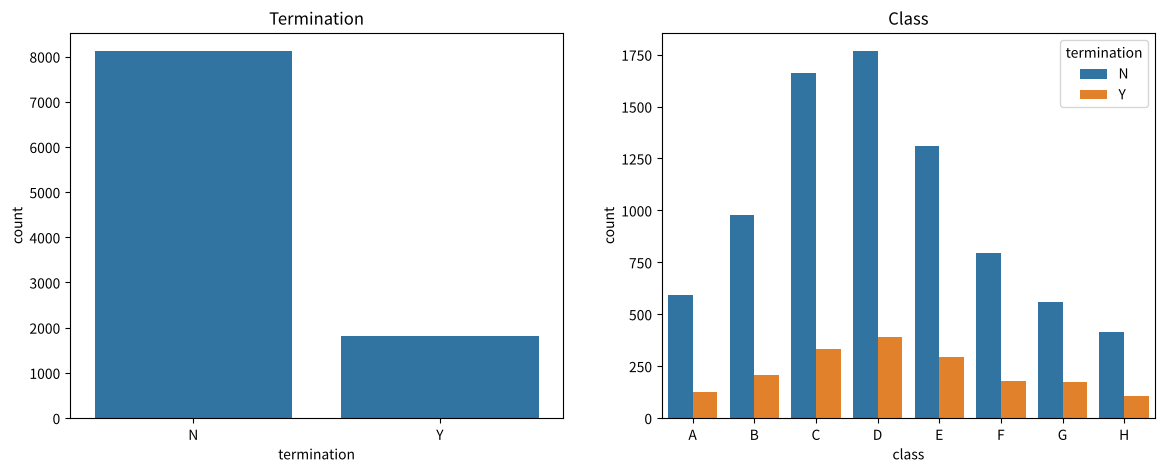

termination
N    8116
Y    1814
Name: count, dtype: int64


In [4]:
# [3번 정답]
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))
sns.countplot(data=df, x='termination', ax=axes[0])
sns.countplot(data=df, x='class', hue='termination', order=sorted(df['class'].dropna().unique()), ax=axes[1])
axes[0].set_title('Termination')
axes[1].set_title('Class')
plt.show()

print(df['termination'].value_counts())
답안3 = 1814

<br>

### **4. 해지 여부(termination)별 평균 청구 금액(avg_bill)의 분포를 boxplot으로 시각화하세요.**
---
- 대상 데이터프레임 : df
- X축: termination, Y축: avg_bill
---

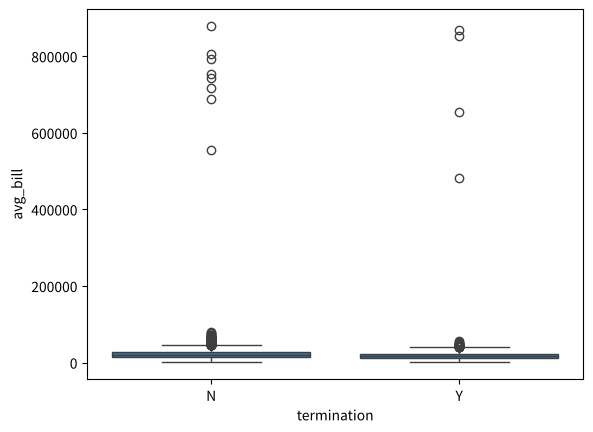

In [5]:
# [4번 정답]
sns.boxplot(data=df, x='termination', y='avg_bill')
plt.show()

<br>

## <font color=blue>**<데이터 전처리>**</font>

### **5. boxplot에서 avg_bill의 이상치가 확인되었고, age에도 비정상적인 값이 있습니다. 아래 가이드에 따라 이상치를 처리하세요.**
---
- 대상 데이터프레임 : df
- avg_bill이 IQR 기준 upper_fence보다 큰 행을 삭제하세요.
- 나이(age)가 100보다 큰 행을 삭제하세요. (결측치는 이 단계에서 삭제하지 않습니다)
- 전처리를 적용한 데이터프레임은 df_temp에 저장하고 index를 초기화하세요.
- 코드의 빈칸 '< blank5-1 >', '< blank5-2 >'를 채우고 실행하세요.
- 빈칸에 들어갈 내용을 '답안5_1', '답안5_2' 변수에, **df_temp의 행 개수**를 '답안5_3' 변수에 저장하세요.
---

In [6]:
# [5번 정답]
q1 = df['avg_bill'].quantile(0.25)
q3 = df['avg_bill'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

df_temp = df.drop(df[df['avg_bill'] > upper_fence].index, axis=0)
df_temp = df_temp.drop(df_temp[df_temp['age'] > 100].index, axis=0)
df_temp.reset_index(drop=True, inplace=True)
print(df_temp.shape)

답안5_1 = 'quantile'
답안5_2 = 'index'
답안5_3 = 9685

(9685, 10)


<br>

### **6. 결측치를 처리하세요.**

- **[6-1] df_temp의 컬럼별 결측치 개수를 확인하고, 전체 결측치 개수를 '답안6_1' 변수에 저장하세요.**
---

In [7]:
# [6-1번 정답]
print(df_temp.isnull().sum())
print(df_temp.isnull().sum().sum())
답안6_1 = 205

class          39
sex             0
age            82
service         0
stop            0
npay            0
avg_bill       60
A_bill         24
B_bill          0
termination     0
dtype: int64
205


- **[6-2] 아래 가이드에 따라 결측치를 처리하세요.**
    - 대상 데이터프레임 : df_temp
    - 고객 등급(class)이 결측인 행은 삭제하세요.
    - 나이(age)의 결측치는 **중앙값**으로 대체하세요.
    - avg_bill, A_bill의 결측치는 각 컬럼의 **평균값**으로 대체하세요.
    - 결과는 df_na에 저장하고, 결측치가 없는지 확인하세요.
---

In [8]:
# [6-2번 정답]
df_na = df_temp.dropna(subset=['class']).copy()
df_na['age'] = df_na['age'].fillna(df_na['age'].median())
df_na['avg_bill'] = df_na['avg_bill'].fillna(df_na['avg_bill'].mean())
df_na['A_bill'] = df_na['A_bill'].fillna(df_na['A_bill'].mean())
print(df_na.isnull().sum())

class          0
sex            0
age            0
service        0
stop           0
npay           0
avg_bill       0
A_bill         0
B_bill         0
termination    0
dtype: int64


<br>

### **7. 범주형 데이터를 모델이 학습할 수 있는 형태로 변환하세요.**
---
- 대상 데이터프레임 : df_na
- 해지 여부(termination)의 값을 'Y'는 1, 'N'은 0으로 변환하세요.
- 원-핫 인코딩 대상 : 'class', 'sex', 'stop', 'npay'
- 원-핫 인코딩이 반영된 결과를 df_preset에 저장하고 info 함수로 확인하세요.
- 아래 코드의 **오류를 정정**하고 실행하세요.
- df_preset의 **컬럼 개수**를 '답안7' 변수에 저장하세요.
---

In [9]:
# [7번 정답]
df_na['termination'] = df_na['termination'].map({'Y': 1, 'N': 0})
df_preset = pd.get_dummies(data=df_na, columns=['class', 'sex', 'stop', 'npay'])
df_preset.info()

답안7 = 20

<class 'pandas.core.frame.DataFrame'>
Index: 9646 entries, 0 to 9684
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          9646 non-null   float64
 1   service      9646 non-null   int64  
 2   avg_bill     9646 non-null   float64
 3   A_bill       9646 non-null   float64
 4   B_bill       9646 non-null   float64
 5   termination  9646 non-null   int64  
 6   class_A      9646 non-null   bool   
 7   class_B      9646 non-null   bool   
 8   class_C      9646 non-null   bool   
 9   class_D      9646 non-null   bool   
 10  class_E      9646 non-null   bool   
 11  class_F      9646 non-null   bool   
 12  class_G      9646 non-null   bool   
 13  class_H      9646 non-null   bool   
 14  sex_F        9646 non-null   bool   
 15  sex_M        9646 non-null   bool   
 16  stop_N       9646 non-null   bool   
 17  stop_Y       9646 non-null   bool   
 18  npay_N       9646 non-null   bool   
 19  npay_Y     

<br>

### **8. 해지 여부(termination)를 레이블 y로, 나머지 컬럼을 피처 X로 할당한 후 훈련/검증 데이터셋으로 분리하세요.**
---
- 대상 데이터프레임 : df_preset
- 훈련데이터셋 : X_train, y_train / 검증데이터셋 : X_valid, y_valid
- 훈련:검증 = 70:30, 난수 시드 42
- 훈련데이터셋과 검증데이터셋의 해지 비율이 같도록 옵션을 설정하세요.
---

In [10]:
# [8번 정답]
from sklearn.model_selection import train_test_split

X = df_preset.drop('termination', axis=1)
y = df_preset['termination']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_valid.shape)

(6752, 19) (2894, 19)


<br>

### **9. StandardScaler로 스케일링하려는데 에러가 납니다. 코드의 오류를 정정하세요.**
---
- sklearn.preprocessing에서 StandardScaler를 import하고 ss 변수에 지정하세요.
- 훈련데이터에 학습(fit)과 변환을, 검증데이터에는 학습된 기준으로 변환만 적용하세요.
- 스케일 반영 후 변수명은 반영 전 변수명을 그대로 사용하세요.
- 스케일링된 검증데이터의 최댓값을 반올림한 결과를 '답안9' 변수에 저장하세요.
---

In [11]:
# [9번 정답]
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
print(round(np.max(X_valid)))

답안9 = 6

6


<br>

## <font color=blue>**<AI 모델링>**</font>

### **10. 해지 여부를 예측하는 DecisionTree, RandomForest 모델을 만들고 하이퍼파라미터를 탐색하세요.**

- **[10-1] DecisionTree 모델을 GridSearchCV로 탐색하고 gs_dt 변수에 저장하세요.**
  - 3-fold Cross Validation (cv=3)
  - 트리의 최대 깊이 후보 : [3, 5, 7, 10]
  - min_samples_split 후보 : [2, 5, 10]
  - scoring='accuracy', n_jobs=-1
  - DecisionTree 난수 시드 : 42
  - 훈련데이터셋으로 학습시키세요.
---

In [12]:
# [10-1번 정답]
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(random_state=42)
param_grid_dt = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10]
}
gs_dt = GridSearchCV(estimator=dt, param_grid=param_grid_dt, cv=3, scoring='accuracy', n_jobs=-1)
gs_dt.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inform

- **[10-2] RandomForest 모델을 GridSearchCV로 탐색하고 gs_rf 변수에 저장하세요.**
  - 3-fold Cross Validation
  - 분류기 개수(n_estimators) 후보 : [100, 200]
  - 트리의 최대 깊이 후보 : [5, 10, 15]
  - scoring='accuracy', n_jobs=-1
  - RandomForest 난수 시드 : 42
  - 아래 코드의 빈칸 '< blank10-1 >', '< blank10-2 >'를 채우고, 빈칸 내용을 '답안10_1', '답안10_2'에 저장하세요.
---

In [13]:
# [10-2번 정답]
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15]
}
gs_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1)
gs_rf.fit(X_train, y_train)

답안10_1 = 'param_grid'
답안10_2 = 'fit'

- **[10-3] GridSearchCV로 찾은 DecisionTree의 최적 max_depth 값을 '답안10_3'에 저장하세요.**
---

In [14]:
# [10-3번 정답]
print(gs_dt.best_params_)
print(gs_rf.best_params_)
답안10_3 = 3

{'max_depth': 3, 'min_samples_split': 2}
{'max_depth': 10, 'n_estimators': 200}


<br>

### **11. RandomForest 모델의 변수중요도를 파악하려는데 에러가 납니다. 코드의 오류를 정정하세요.**
---
- gs_rf의 best_estimator_를 사용하세요.
- 변수중요도와 변수 이름을 매핑한 DataFrame을 만들고, 중요도 기준 내림차순으로 top 10을 선정하세요.
- 막대 그래프로 시각화하고, 가장 중요한 feature명을 '답안11' 변수에 저장하세요.
---

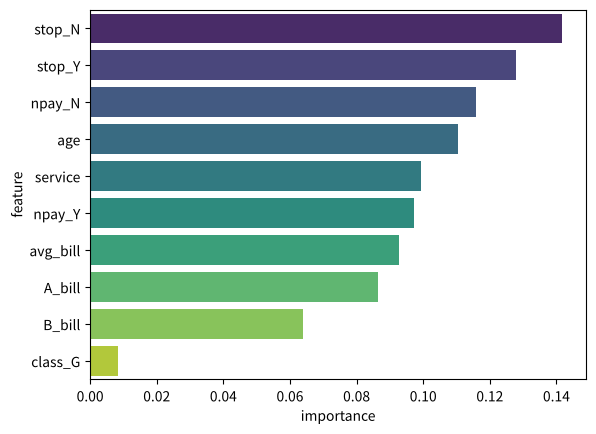

In [15]:
# [11번 정답]
fi = pd.DataFrame({'feature': X.columns, 'importance': gs_rf.best_estimator_.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi, palette='viridis')
plt.show()

답안11 = 'stop_N'

<br>

### **12. 두 모델의 성능을 검증데이터로 평가하세요.**
---
- gs_dt, gs_rf의 best_estimator_를 사용하세요.
- 각 모델의 예측값을 y_pred_dt, y_pred_rf 에 저장하세요.
- 각 모델의 Accuracy를 dt_acc, rf_acc에, F1 score를 dt_f1, rf_f1에 저장하고 출력하세요.
- **F1 score**가 더 높은 모델의 이름('DecisionTree' 또는 'RandomForest')을 '답안12'에 저장하세요.
- 아래 코드의 오류를 정정하세요.
---

In [16]:
# [12번 정답]
from sklearn.metrics import accuracy_score, f1_score

y_pred_dt = gs_dt.best_estimator_.predict(X_valid)
y_pred_rf = gs_rf.best_estimator_.predict(X_valid)

dt_acc = accuracy_score(y_valid, y_pred_dt)
rf_acc = accuracy_score(y_valid, y_pred_rf)
dt_f1 = f1_score(y_valid, y_pred_dt)
rf_f1 = f1_score(y_valid, y_pred_rf)

print("DecisionTree acc =", dt_acc, "/ f1 =", dt_f1)
print("RandomForest acc =", rf_acc, "/ f1 =", rf_f1)

답안12 = 'RandomForest'

DecisionTree acc = 0.8807878369039391 / f1 = 0.6318036286019211
RandomForest acc = 0.8825155494125777 / f1 = 0.6390658174097664


> 💡 **해설**: 해지(1)가 약 18%뿐인 불균형 데이터라서, 모두 0으로 예측해도 Accuracy가 82%쯤 나옵니다.
> 그래서 Accuracy만 보면 두 모델 차이가 작지만, **F1/Recall**을 보면 해지 고객을 얼마나 잡아내는지 차이가 드러납니다.

<br>

### **13. 성능이 더 좋은 모델의 상세 성능을 확인하세요.**
---
- 답안12에서 고른 모델의 예측값으로 confusion_matrix와 classification_report를 출력하세요.
- classification_report에서 **해지(1) 클래스의 recall** 값을 소수점 둘째 자리까지 '답안13'에 저장하세요.
    - 예시) 답안13 = 0.12
---

In [17]:
# [13번 정답]
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_valid, y_pred_rf))
print(classification_report(y_valid, y_pred_rf))

답안13 = 0.56

[[2253  103]
 [ 237  301]]
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      2356
           1       0.75      0.56      0.64       538

    accuracy                           0.88      2894
   macro avg       0.82      0.76      0.78      2894
weighted avg       0.88      0.88      0.88      2894



<br>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**